# Cross-Sectional ML for Long-Short Equity Selection
## Part 2 — Model selection, tuning, and held-out evaluation

Runs on `data/model_train.csv` and `data/model_test.csv`, both written by
Part 1. No network, no credentials.

### The constraint behind every choice below

The training set has **13,300 rows but only 665 distinct trading days**. The
20 names on a given day share one market shock and were explicitly demeaned
*against each other*, so rows within a day are close to the opposite of
independent draws. The effective sample size is far nearer 665 than 13,300 —
roughly **17 observations per feature, not 350**.

That drives three decisions:

1. **Grids are deliberately small and regularisation is heavy.** With this
   much noise, a large grid mostly searches for the luckiest fold split.
2. **Every t-statistic is computed across days, never across rows.** Pooling
   rows would inflate it by roughly $\sqrt{20}$.
3. **Model selection is on rank IC, not MAE.** The strategy monetises the
   *ordering* of names within a day. A model that predicts ~0 for everything
   scores excellent MAE and is worth nothing to trade — MAE alone would pick
   exactly the wrong winner. All four required metrics are reported; only the
   selection criterion is opinionated.

In [2]:
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression
from sklearn.linear_model import ElasticNet, Ridge, Lasso   # ADDED: Ridge, Lasso
from sklearn.cross_decomposition import PLSRegression       # ADDED: PLS
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

RANDOM_STATE = 0
DATA = "data"

train = pd.read_csv(f"{DATA}/model_train.csv", parse_dates=["date"]).reset_index(drop=True)
test = pd.read_csv(f"{DATA}/model_test.csv", parse_dates=["date"]).reset_index(drop=True)
meta = json.load(open(f"{DATA}/feature_meta.json"))
FEATURES = meta["selected"]

X_tr, y_tr, d_tr = train[FEATURES], train["target"].values, train["date"].values
X_te, y_te, d_te = test[FEATURES], test["target"].values, test["date"].values

print(f"train {X_tr.shape[0]:,} rows x {X_tr.shape[1]} features | "
      f"{train['date'].nunique():,} days | {train['ticker'].nunique()} names")
print(f"test  {X_te.shape[0]:,} rows                  | "
      f"{test['date'].nunique():,} days")
print(f"\ntarget sd {y_tr.std():.5f}  kurtosis {pd.Series(y_tr).kurt():.1f}")
print(f"features with NaN: {int(X_tr.isna().any().sum())} of {len(FEATURES)}")

train 13,300 rows x 38 features | 665 days | 20 names
test  4,960 rows                  | 248 days

target sd 0.02400  kurtosis 36.5
features with NaN: 8 of 38


## 1. Metrics

Our target is a one-day log return — it *is* the change. So `sign(target)` is used directly.

Quintiles are cut on the **absolute actual move** (Q1 tiny … Q5 large), and the naive baseline is always-predict-the-majority-direction, computed globally and within each
bucket.

In [3]:
def mae(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))))


def profit_factor(returns):
    """Gross profit / gross loss. >1 means winners outweigh losers."""
    r = np.asarray(returns, float)
    r = r[np.isfinite(r)]
    gain, loss = r[r > 0].sum(), -r[r < 0].sum()
    if loss == 0:
        return np.inf if gain > 0 else np.nan
    return float(gain / loss)


def signal_profit_factor(y_true, y_pred):
    """PF of the naive rule 'take the sign of the prediction'."""
    return profit_factor(np.sign(np.asarray(y_pred, float)) * np.asarray(y_true, float))


def rank_ic(y_true, y_pred, dates):
    """
    Mean DAILY cross-sectional Spearman, its t-stat, the number of days scored,
    and how many of those days the model gave no ordering on.

    Computed per day then averaged -- never pooled across all rows. Pooling
    would let a high-dispersion day dominate and would mix across-day variation
    into what is meant to be a within-day ranking score. The t-stat uses the
    spread of DAILY ICs, so its degrees of freedom are days, not rows.
    """
    df = pd.DataFrame({"d": np.asarray(dates), "y": np.asarray(y_true, float),
                       "p": np.asarray(y_pred, float)}).dropna()
    ics, degenerate = [], 0
    for _, g in df.groupby("d"):
        if len(g) < 3 or g.y.nunique() < 2:
            continue                      # undefined through no fault of the model
        if g.p.nunique() < 2:
            # The model gave the same number to all 20 names, so it supplied no
            # ordering at all that day. That scores ZERO -- it must not be
            # skipped. Skipping silently rewards degeneracy: a model that
            # collapses to a constant on 80% of days would then be judged only
            # on the 20% where it happened to do something, and would win.
            ics.append(0.0)
            degenerate += 1
            continue
        ic = spearmanr(g.p, g.y).statistic
        ics.append(ic if np.isfinite(ic) else 0.0)
    ics = np.asarray(ics)
    if len(ics) < 2:
        return np.nan, np.nan, len(ics), degenerate
    t = ics.mean() / (ics.std(ddof=1) / np.sqrt(len(ics)))
    return float(ics.mean()), float(t), len(ics), degenerate


def global_majority_baseline(y_true, y_pred):
    y, p = np.asarray(y_true, float), np.asarray(y_pred, float)
    ok = np.isfinite(y) & np.isfinite(p)
    y, p = y[ok], p[ok]
    n_up, n_dn = int((y > 0).sum()), int((y < 0).sum())
    return {"n": len(y), "n_up": n_up, "n_down": n_dn,
            "majority": "up" if n_up >= n_dn else "down",
            "naive_hit_rate": max(n_up, n_dn) / len(y) * 100,
            "model_hit_rate": float((np.sign(y) == np.sign(p)).sum()) / len(y) * 100}


def directional_accuracy_by_quantile(y_true, y_pred, q=5):
    """Hit rate by ABSOLUTE-MOVE quintile vs the majority baseline in that bucket."""
    df = pd.DataFrame({"true": np.asarray(y_true, float),
                       "pred": np.asarray(y_pred, float)}).dropna()
    df["correct"] = np.sign(df["true"]) == np.sign(df["pred"])
    df["abs_move"] = df["true"].abs()
    df["q"] = pd.qcut(df["abs_move"], q=q, labels=False, duplicates="drop")
    bins = sorted(df["q"].dropna().unique())
    names = ["Q1 (tiny)", "Q2", "Q3", "Q4", "Q5 (large)"][:q]
    if len(bins) != len(names):
        names = [f"Q{i+1}" for i in range(len(bins))]
        names[0] += " (tiny)"; names[-1] += " (large)"
    df["q"] = df["q"].map(dict(zip(bins, names)))
    out = (df.groupby("q", observed=True)["correct"].agg(["mean", "count"])
             .rename(columns={"mean": "Hit Rate", "count": "N"}))
    out["% of Total"] = (out["N"] / len(df) * 100).round(1)
    out["Naive"] = (df.groupby("q", observed=True)["true"]
                    .apply(lambda g: max((g > 0).sum(), (g < 0).sum()) / len(g)))
    out["Skill"] = out["Hit Rate"] - out["Naive"]
    out["Mean |move|"] = df.groupby("q", observed=True)["abs_move"].mean()
    return out.reindex([n for n in names if n in out.index])


def report(y_true, y_pred, dates, label="", q=5, verbose=True):
    ic, t, ndays, ndeg = rank_ic(y_true, y_pred, dates)
    g = global_majority_baseline(y_true, y_pred)
    res = {"label": label, "MAE": mae(y_true, y_pred),
           "ProfitFactor": signal_profit_factor(y_true, y_pred),
           "RankIC": ic, "RankIC_t": t, "n_days": ndays, "DegenDays": ndeg,
           "DirAcc": g["model_hit_rate"], "NaiveDirAcc": g["naive_hit_rate"],
           "Skill": g["model_hit_rate"] - g["naive_hit_rate"]}
    if verbose:
        print(f"\n{'=' * 68}\n{label}\n{'=' * 68}")
        print(f"  Mean absolute error : {res['MAE']:.6f}")
        print(f"  Profit Factor       : {res['ProfitFactor']:.4f}")
        print(f"  Spearman Rank IC    : {res['RankIC']:+.4f}  "
              f"(t = {res['RankIC_t']:+.2f} over {ndays} days"
              + (f", {ndeg} with NO ordering)" if ndeg else ")"))
        print(f"  Naive hit rate      : {g['naive_hit_rate']:.2f}%  "
              f"(always predict '{g['majority']}')")
        print(f"  Model hit rate      : {g['model_hit_rate']:.2f}%")
        print(f"  Skill vs naive      : {res['Skill']:+.2f} pct points")
        print(f"\n  Directional accuracy by absolute-move quintile:")
        print(directional_accuracy_by_quantile(y_true, y_pred, q)
              .to_string(float_format=lambda x: f"{x:8.4f}"))
    res["by_quantile"] = directional_accuracy_by_quantile(y_true, y_pred, q)
    return res


print("Metrics defined: MAE, Profit Factor, Spearman rank IC, "
      "directional accuracy by quantile.")

Metrics defined: MAE, Profit Factor, Spearman rank IC, directional accuracy by quantile.


## 2. Cross-validation — `TimeSeriesSplit` over dates

Because sklearn's row-wise `TimeSeriesSplit` split time by rows instead of dates, with 20 stocks per day it can put the same date on both sides of a fold boundary. This will cause bad leakage and inflation.

So we use a splitter by **dates**, with an **embargo** after each training block so the last training target (which looks one day ahead) cannot reach into validation.

The embargo: 1 day is required by the target's one-day look-ahead; we use **5** (one trading week, ≈0.75% of the sample) following the López de Prado (Chapter 7, Advances in Financial Machine Learning) embargo convention, covering short-horizon autocorrelation and near-duplicate boundary rows from persistent features; a sensitivity over 0–10 days shows the choice is immaterial.

In [ ]:
class DateGroupedTimeSeriesSplit:
    """Expanding-window TimeSeriesSplit whose folds break between whole days."""

    def __init__(self, n_splits=5, embargo=5):
        self.n_splits, self.embargo = n_splits, embargo

    def get_n_splits(self, X=None, y=None, groups=None):
        return self.n_splits

    def split(self, X, y=None, groups=None):
        g = pd.Series(np.asarray(groups))
        udates = np.array(sorted(g.unique()))
        n, idx = len(udates), np.arange(len(g))
        fold = n // (self.n_splits + 1)
        for k in range(self.n_splits):
            tr_end = fold * (k + 1)
            va_beg = tr_end + self.embargo
            va_end = min(va_beg + fold, n)
            if va_beg >= n:
                break
            tr = idx[g.isin(udates[:tr_end]).to_numpy()]
            va = idx[g.isin(udates[va_beg:va_end]).to_numpy()]
            if len(tr) and len(va):
                yield tr, va

# embargo of 5 days between train and validation folds to avoid leakage
# sensitivity test of embargo = 0-10 shows the choice is immaterial
CV = DateGroupedTimeSeriesSplit(n_splits=5, embargo=5)

print("Fold structure (expanding window, 5-day embargo):")
for k, (tr, va) in enumerate(CV.split(X_tr, y_tr, groups=d_tr)):
    td, vd = pd.Series(d_tr[tr]), pd.Series(d_tr[va])
    gap = (vd.min() - td.max()).days
    print(f"  fold {k}: train {len(tr):>6,} rows / {td.nunique():>3} days "
          f"({td.min():%Y-%m-%d}..{td.max():%Y-%m-%d})  ->  "
          f"val {len(va):>5,} rows / {vd.nunique():>3} days   gap {gap}d")
    assert td.max() < vd.min(), "fold leaks: train overlaps validation"
print("\n[ok] every fold boundary falls between whole trading days")

Fold structure (expanding window, 5-day embargo):
  fold 0: train  2,200 rows / 110 days (2022-01-03..2022-06-09)  ->  val 2,200 rows / 110 days   gap 8d
  fold 1: train  4,400 rows / 220 days (2022-01-03..2022-11-15)  ->  val 2,200 rows / 110 days   gap 8d
  fold 2: train  6,600 rows / 330 days (2022-01-03..2023-04-26)  ->  val 2,200 rows / 110 days   gap 8d
  fold 3: train  8,800 rows / 440 days (2022-01-03..2023-10-03)  ->  val 2,200 rows / 110 days   gap 8d
  fold 4: train 11,000 rows / 550 days (2022-01-03..2024-03-12)  ->  val 2,200 rows / 110 days   gap 8d

[ok] every fold boundary falls between whole trading days


## 3. The training target

Kurtosis is **36.5** — a handful of earnings gaps carry an enormous share of the squared error.

So the **training** target is winsorised at ±5 sd to stablize the performance. But for every metric, and the entire test set, uses the **raw** target.

In [5]:
WINSOR_SD = 5.0
sd = y_tr.std()
y_tr_w = np.clip(y_tr, -WINSOR_SD * sd, WINSOR_SD * sd)
n_clip = int((np.abs(y_tr) > WINSOR_SD * sd).sum())

print(f"Training target winsorised at +/-{WINSOR_SD} sd (= {WINSOR_SD * sd:.4f}):")
print(f"  {n_clip:,} of {len(y_tr):,} rows clipped ({100 * n_clip / len(y_tr):.2f}%)")
print(f"  kurtosis {pd.Series(y_tr).kurt():.1f} -> {pd.Series(y_tr_w).kurt():.1f}")
print(f"  sd       {y_tr.std():.5f} -> {y_tr_w.std():.5f}")
print("\nNOTE: the test target is left RAW. So is every target used for scoring.")

# the full-train clip is now used ONLY for the single final refit on the whole training block. 
# The CV loop below recomputes the clip INSIDE each fold to avoid data leakage issue.
print("NOTE: the CV loop re-winsorises per fold; this clip is for the final refit only.")

Training target winsorised at +/-5.0 sd (= 0.1200):
  52 of 13,300 rows clipped (0.39%)
  kurtosis 36.5 -> 5.6
  sd       0.02400 -> 0.02197

NOTE: the test target is left RAW. So is every target used for scoring.
NOTE: the CV loop re-winsorises per fold; this clip is for the final refit only.


## 4. The model

| Model | Pipeline | Needs scaling |
|---|---|---|
| LightGBM | raw features — native NaN handling | no |
| RandomForest | impute → model | no |
| ElasticNet | impute → scale → `SelectKBest(f_regression)` → model | **yes** |
| Ridge | impute → scale → model | **yes** |
| Lasso | impute → scale → model (embedded sparse selection) | **yes** |
| PLS | impute → scale → model (supervised extraction) | **yes** |
| SVR (RBF) | impute → scale → `SelectKBest(mutual_info)` → model | **yes** |
| Keras MLP | impute → scale → `SelectKBest(mutual_info)` → model | **yes** |

**LightGBM/ RandomForest.**: tree-based models

**ElasticNet/ Ridge / Lasso.**: complete the regularized linear family

**PLS.** PLS is its supervised version of PCA. PLS components chase *covariance with the target* — the relevant direction for a demeaned target. It's good for addressing multicolinearity and high-dimensional sets with limited samples.

**SVR/ Keras MLP**: non-linear models.

**Why no Transformer.** Transformer targets *sequences*, and it's too strong for our notebook's own doctrine — small grids, heavy regularisation, ~17 observations per feature — and would mostly add selection noise. It stays on the future-work slide.

`f_regression` for the linear model and `mutual_info_regression` for the
non-linear ones, exactly as the brief specifies.



**Other implementation concerns.**

**Target scaling.** Every pipeline is wrapped in a `TransformedTargetRegressor`
that standardises $y$ during cross-validation. This is because the target only has sd 0.024 while most machine learning models assume a default sd to be 1. Without standardization every regularisation constant — ElasticNet's `alpha`, SVR's `epsilon`, the Huber delta — would have to be quoted in units nobody can reason about.

**SVR's epsilon.** The default `epsilon=0.1` is **4.2× the target's standard
deviation**: nearly every point falls inside the tube, and SVR silently returns a
near-constant prediction while looking perfectly converged. On 8,000 rows it
kept 59 support vectors at the default versus 7,622 at `epsilon=0.001`. With the
target standardised the default becomes sane, and epsilon is tuned anyway.

**Imputation.** Median-imputing a per-day cross-sectionally standardised feature
fills in approximately **zero**, which reads as "this name was average that day".
That is a deliberate neutral default, not an accident.

In [6]:
def mi_score(X, y):
    return mutual_info_regression(X, y, random_state=RANDOM_STATE)


# MLP
class KerasMLP(BaseEstimator, RegressorMixin):
    """
    Minimal sklearn-compatible Keras regressor.

      loss            Huber. The target's kurtosis is 36.5, so MSE would let a
                      few extreme days dominate the gradient.
      penalties       L2 weight decay on every dense layer, plus dropout and
                      early stopping on held-out training-fold data.
      sample weights  proportional to |y|, normalised to mean 1. The strategy
                      only ever trades the extreme quantiles, so the large
                      movers are the observations worth getting right.
    """

    def __init__(self, hidden=(64, 32), dropout=0.2, l2=1e-4, lr=1e-3,
                 epochs=200, batch_size=256, huber_delta=1.0,
                 sample_weighting=True, patience=12, seed=RANDOM_STATE):
        self.hidden, self.dropout, self.l2, self.lr = hidden, dropout, l2, lr
        self.epochs, self.batch_size = epochs, batch_size
        self.huber_delta, self.sample_weighting = huber_delta, sample_weighting
        self.patience, self.seed = patience, seed

    def fit(self, X, y):
        import keras
        from keras import layers, regularizers
        keras.utils.set_random_seed(self.seed)
        X = np.asarray(X, dtype="float32")
        y = np.asarray(y, dtype="float32").ravel()

        # the rows arrive TICKER-MAJOR (every date of one
        # ticker, then the next ticker), and Keras' validation_split carves the
        # LAST fraction of rows BEFORE any shuffling. This meant
        # early stopping was always scored on the same ~3 alphabetical tickers
        # (WRBY/WSBC/XPO) across ALL dates -- not the "chronological tail" the
        # old comment claimed -- and shuffle=False made every batch a single
        # ticker's contiguous block of rows. To fix this, we permute rows with a
        # seed so the 15% early-stopping slice is an unbiased random sample of
        # names and dates (every row is still a training-fold row, so nothing
        # leaks across folds), and let Keras shuffle the training batches.
        rng = np.random.default_rng(self.seed)
        perm = rng.permutation(len(X))
        X, y = X[perm], y[perm]

        net = keras.Sequential([keras.Input(shape=(X.shape[1],))])
        for h in self.hidden:
            net.add(layers.Dense(h, activation="relu",
                                 kernel_regularizer=regularizers.l2(self.l2)))
            net.add(layers.Dropout(self.dropout))
        net.add(layers.Dense(1))
        net.compile(optimizer=keras.optimizers.Adam(self.lr),
                    loss=keras.losses.Huber(delta=self.huber_delta))

        w = None
        if self.sample_weighting:
            w = np.abs(y)
            w = w / w.mean() if w.mean() > 0 else np.ones_like(y)

        net.fit(X, y, sample_weight=w, epochs=self.epochs,
                batch_size=self.batch_size, verbose=0, shuffle=True,
                validation_split=0.15,
                callbacks=[keras.callbacks.EarlyStopping(
                    monitor="val_loss", patience=self.patience,
                    restore_best_weights=True)])
        self.model_ = net
        return self

    def predict(self, X):
        return self.model_.predict(np.asarray(X, dtype="float32"),
                                   verbose=0).ravel()


def wrap(estimator):
    """Standardise y during fitting, invert on predict. Refit inside each fold."""
    return TransformedTargetRegressor(regressor=estimator, transformer=StandardScaler())


# Built fresh on every call. Sharing one estimator instance across pipelines
# invites cross-contamination between fits, and costs nothing to avoid.
def IMPUTE():
    return ("impute", SimpleImputer(strategy="median"))


def SCALE():
    return ("scale", StandardScaler())

In [7]:
MODELS = {
    "LightGBM": {
        "pipe": lambda **p: wrap(LGBMRegressor(
            random_state=RANDOM_STATE, verbose=-1, n_estimators=400, **p)),
        "grid": [{"num_leaves": nl, "learning_rate": lr, "min_child_samples": mcs,
                  "reg_lambda": 5.0, "colsample_bytree": 0.7, "subsample": 0.8,
                  "subsample_freq": 1}
                 for nl in (7, 15) for lr in (0.02, 0.05) for mcs in (100, 300)],
        "scaled": False,
    },
    "RandomForest": {
        "pipe": lambda **p: wrap(Pipeline([
            IMPUTE(), ("model", RandomForestRegressor(
                n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, **p))])),
        "grid": [{"model__max_depth": d, "model__min_samples_leaf": leaf,
                  "model__max_features": 0.4}
                 for d in (4, 8) for leaf in (50, 200)],
        "scaled": False,
    },
    "ElasticNet": {
        "pipe": lambda **p: wrap(Pipeline([
            IMPUTE(), SCALE(), ("select", SelectKBest(score_func=f_regression)),
            ("model", ElasticNet(max_iter=5000, random_state=RANDOM_STATE))])),
        "grid": [{"select__k": k, "model__alpha": a, "model__l1_ratio": l1}
                 for k in (15, 38) for a in (1e-4, 1e-3, 1e-2) for l1 in (0.15, 0.9)],
        "scaled": True,
    },
    "Ridge": {
        "pipe": lambda **p: wrap(Pipeline([
            IMPUTE(), SCALE(), ("model", Ridge(max_iter=5000))])),
        "grid": [{"model__alpha": a} for a in (0.03, 0.3, 3.0, 30.0)],
        "scaled": True,
    },
    "Lasso": {
        "pipe": lambda **p: wrap(Pipeline([
            IMPUTE(), SCALE(), ("model", Lasso(max_iter=50000,
                                               random_state=RANDOM_STATE))])),
        "grid": [{"model__alpha": a} for a in (1e-4, 1e-3, 1e-2, 1e-1)],
        "scaled": True,
    },
    "PLS": {
        "pipe": lambda **p: wrap(Pipeline([
            IMPUTE(), SCALE(), ("model", PLSRegression(scale=False))])),
        "grid": [{"model__n_components": k} for k in (5, 10, 20, 38)],
        "scaled": True,
    },
    "SVR": {
        "pipe": lambda **p: wrap(Pipeline([
            IMPUTE(), SCALE(), ("select", SelectKBest(score_func=mi_score)),
            ("model", SVR(kernel="rbf", cache_size=1000))])),
        "grid": [{"select__k": k, "model__C": c, "model__epsilon": e,
                  "model__gamma": "scale"}
                 for k in (15,) for c in (0.3, 1.0, 3.0) for e in (0.05, 0.2)],
        "scaled": True,
    },
    "KerasMLP": {
        "pipe": lambda **p: wrap(Pipeline([
            IMPUTE(), SCALE(), ("select", SelectKBest(score_func=mi_score)),
            ("model", KerasMLP())])),
        "grid": [{"select__k": k, "model__hidden": h, "model__dropout": dr,
                  "model__l2": l2}
                 for k in (15, 38) for h in ((32,), (64, 32))
                 for dr in (0.3,) for l2 in (1e-3,)],
        "scaled": True,
    },
}

for name, spec in MODELS.items():
    print(f"  {name:14s} {len(spec['grid']):>2} configs x 5 folds = "
          f"{len(spec['grid']) * 5:>3} fits   scaling: {spec['scaled']}")
print(f"\nTotal fits: {sum(len(s['grid']) for s in MODELS.values()) * 5}")

  LightGBM        8 configs x 5 folds =  40 fits   scaling: False
  RandomForest    4 configs x 5 folds =  20 fits   scaling: False
  ElasticNet     12 configs x 5 folds =  60 fits   scaling: True
  Ridge           4 configs x 5 folds =  20 fits   scaling: True
  Lasso           4 configs x 5 folds =  20 fits   scaling: True
  PLS             4 configs x 5 folds =  20 fits   scaling: True
  SVR             6 configs x 5 folds =  30 fits   scaling: True
  KerasMLP        4 configs x 5 folds =  20 fits   scaling: True

Total fits: 230


## 5. Manual grid-search cross-validation loop

To hand back **out-of-fold predictions**, each configuration is fitted on every fold's training block and predicts its validation block. The union of validation blocks forms one OOF prediction vector, scored by rank IC against the **raw** target.

In [9]:
def build(model_spec, params):
    """Instantiate a model with `params` applied.

    Every pipeline is wrapped in a TransformedTargetRegressor, so each grid key
    picks up a `regressor__` prefix on its way in.
    """
    est = clone(model_spec["pipe"]())
    est.set_params(**{f"regressor__{k}": v for k, v in params.items()})
    return est


def cv_oof(model_spec, params, X, y_raw, dates, cv, winsor_sd=5.0):
    """Fit one configuration across all folds; return its out-of-fold predictions.
    The winsorisation clip is computed INSIDE each fold to avoid any data leakage.
    """
    oof = np.full(len(y_raw), np.nan)
    for tr, va in cv.split(X, y_raw, groups=dates):
        fold_sd = y_raw[tr].std()
        y_fit = np.clip(y_raw[tr], -winsor_sd * fold_sd, winsor_sd * fold_sd)
        est = build(model_spec, params)
        est.fit(X.iloc[tr], y_fit)
        oof[va] = est.predict(X.iloc[va])
    return oof


results, oof_store = [], {}

for name, spec in MODELS.items():
    t0 = time.time()
    best = None
    for params in spec["grid"]:
        oof = cv_oof(spec, params, X_tr, y_tr, d_tr, CV)
        m = np.isfinite(oof)
        ic, t, nd, _ = rank_ic(y_tr[m], oof[m], d_tr[m])
        # a NaN first configuration used to stick as "best"
        # for the rest of the grid, because (ic > NaN) is always False.
        # Explicitly displace a non-finite incumbent before comparing.
        if (best is None or not np.isfinite(best["RankIC"])
                or (np.isfinite(ic) and ic > best["RankIC"])):
            best = {"params": params, "RankIC": ic, "RankIC_t": t, "oof": oof}
    m = np.isfinite(best["oof"])
    r = report(y_tr[m], best["oof"][m], d_tr[m], label=f"{name} (out-of-fold)",
               verbose=False)
    r["params"] = best["params"]
    r["secs"] = time.time() - t0
    results.append(r)
    oof_store[name] = best["oof"]
    print(f"{name:14s} rankIC {r['RankIC']:+.4f} (t {r['RankIC_t']:+.2f})  "
          f"PF {r['ProfitFactor']:.4f}  MAE {r['MAE']:.6f}  "
          f"dir {r['DirAcc']:.2f}%  [{r['secs']:.0f}s]")
    print(f"               best: {best['params']}")

LightGBM       rankIC +0.0259 (t +2.18)  PF 1.0930  MAE 0.015357  dir 51.08%  [14s]
               best: {'num_leaves': 15, 'learning_rate': 0.05, 'min_child_samples': 300, 'reg_lambda': 5.0, 'colsample_bytree': 0.7, 'subsample': 0.8, 'subsample_freq': 1}
RandomForest   rankIC +0.0273 (t +2.31)  PF 1.0374  MAE 0.014838  dir 50.45%  [24s]
               best: {'model__max_depth': 4, 'model__min_samples_leaf': 50, 'model__max_features': 0.4}
ElasticNet     rankIC +0.0208 (t +1.69)  PF 1.0672  MAE 0.014856  dir 51.30%  [17s]
               best: {'select__k': 15, 'model__alpha': 0.01, 'model__l1_ratio': 0.9}
Ridge          rankIC +0.0215 (t +1.74)  PF 1.0921  MAE 0.014957  dir 51.13%  [3s]
               best: {'model__alpha': 30.0}
Lasso          rankIC +0.0226 (t +1.85)  PF 1.0521  MAE 0.014862  dir 50.68%  [5s]
               best: {'model__alpha': 0.01}
PLS            rankIC +0.0245 (t +2.01)  PF 1.0488  MAE 0.014946  dir 50.65%  [4s]
               best: {'model__n_components': 5}
SV

## 6. Validation comparison, plus a rank-average ensemble

The ensemble averages the three best models' **cross-sectional ranks** within
each day rather than their raw predictions. The models are on different scales
and the strategy only ever consumes an ordering, so averaging ranks is both the
scale-free choice and the one that matches what gets traded.

In [ ]:
val = pd.DataFrame([{k: r[k] for k in
                     ["label", "MAE", "ProfitFactor", "RankIC", "RankIC_t",
                      "DirAcc", "NaiveDirAcc", "Skill", "n_days", "DegenDays"]}
                    for r in results])
val["label"] = [r["label"].replace(" (out-of-fold)", "") for r in results]
val = val.sort_values("RankIC", ascending=False).reset_index(drop=True)

# --- ensemble of the top 3 -----------------------------------------------
# Each model's predictions are standardised WITHIN each day, then averaged, then
# put back on a return scale.
#
# The per-day standardisation is what makes the combination meaningful: the
# models predict on quite different scales, so a raw average would just be the
# widest-spread model wearing a disguise. The rescale at the end matters for a
# duller reason -- an average of pct-ranks lives in [0, 1], which makes MAE
# meaningless and every predicted sign positive, so Profit Factor and
# directional accuracy would both be garbage.
top3 = val.head(3)["label"].tolist()
common = np.all([np.isfinite(oof_store[n]) for n in top3], axis=0)
dser = pd.Series(d_tr)

zs = []
for n in top3:
    sr = pd.Series(oof_store[n])
    grp = sr.groupby(dser)
    zs.append(((sr - grp.transform("mean")) / grp.transform("std")).to_numpy())
ens_z = np.nanmean(np.vstack(zs), axis=0)

# Back onto a return scale: match the average spread of the constituents.
scale = float(np.nanmean([np.nanstd(oof_store[n]) for n in top3]))
ens_pred = ens_z * scale

r_ens = report(y_tr[common], ens_pred[common], d_tr[common],
               label=f"Ensemble (per-day z-avg of {', '.join(top3)})", verbose=False)
val = pd.concat([val, pd.DataFrame([{k: r_ens[k] for k in val.columns}])],
                ignore_index=True)
val.loc[val.index[-1], "label"] = f"Ensemble ({'+'.join(top3)})"

print("VALIDATION (out-of-fold) -- ranked by Spearman rank IC\n")
print(val.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\nNOTE: MAE is reported but it is NOT the selection criterion.")
print("A model predicting ~0 everywhere wins on MAE and is")
print("worth nothing to trade -- compare the MAE column against RankIC to see")
print("how weakly the two are related.")

VALIDATION (out-of-fold) -- ranked by Spearman rank IC

                                    label    MAE  ProfitFactor  RankIC  RankIC_t  DirAcc  NaiveDirAcc   Skill  n_days  DegenDays
                                 KerasMLP 0.0157        1.0584  0.0300    2.5074 51.2364      50.6182  0.6182     550          0
                             RandomForest 0.0148        1.0374  0.0273    2.3120 50.4455      50.6182 -0.1727     550          0
                                 LightGBM 0.0154        1.0930  0.0259    2.1843 51.0818      50.6182  0.4636     550          0
                                      PLS 0.0149        1.0488  0.0245    2.0135 50.6455      50.6182  0.0273     550          0
                                    Lasso 0.0149        1.0521  0.0226    1.8473 50.6818      50.6182  0.0636     550          0
                                    Ridge 0.0150        1.0921  0.0215    1.7440 51.1273      50.6182  0.5091     550          0
                               ElasticNet

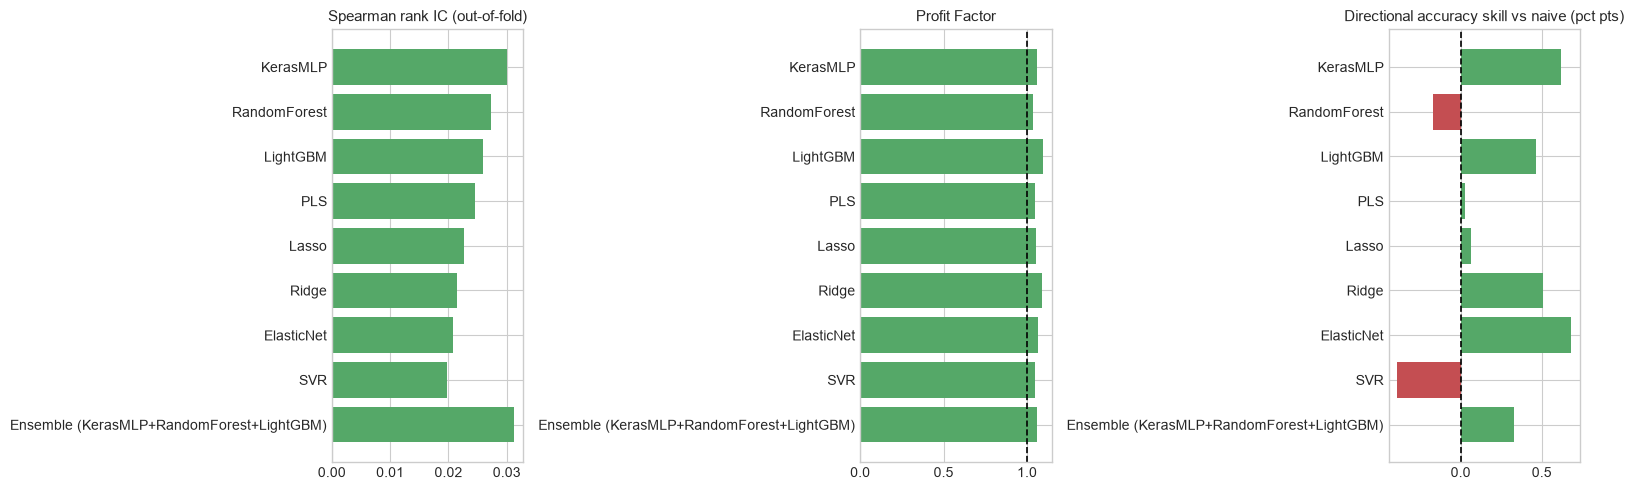

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
plot_df = val.iloc[::-1]
for ax, (col, title, ref) in zip(axes, [
        ("RankIC", "Spearman rank IC (out-of-fold)", 0.0),
        ("ProfitFactor", "Profit Factor", 1.0),
        ("Skill", "Directional accuracy skill vs naive (pct pts)", 0.0)]):
    colors = ["#55A868" if v > ref else "#C44E52" for v in plot_df[col]]
    ax.barh(plot_df["label"], plot_df[col], color=colors)
    ax.axvline(ref, color="black", linestyle="--", lw=1.2)
    ax.set_title(title, fontsize=11)
plt.tight_layout()
plt.show()

## 7. Fine-tuning the selected model

A second, finer manual grid around the winner's neighbourhood. Kept small on
purpose: with 665 effective days, a wide search mostly finds the configuration
best suited to this particular fold split, and that gain does not survive
out-of-sample.

This stage selects the best of a handful of
configurations **on the same folds** stage 1 already ranked models on, so the
tuned validation IC below is a second-order maximum — upward-biased by
selection in exactly the way §9 describes for stage 1. It does not touch the
test set (still untouched at this point), but the validation number should be
read as optimistic; the honest estimate of skill is the test row alone.

In [13]:
# The ensemble is reported as a comparison, not carried forward: this is because SHAP and
# model-selection narrative both need one estimator, and on 665 effective days
# any ensemble edge is well inside the noise. Select the best SINGLE model.
singles = val[~val["label"].str.startswith("Ensemble")].reset_index(drop=True)
WINNER = singles.iloc[0]["label"]
ens_row = val[val["label"].str.startswith("Ensemble")].iloc[0]

print(f"Selected model: {WINNER}")
print(f"  best single model, out-of-fold rank IC = {singles.iloc[0]['RankIC']:+.4f}")
print(f"  rank-average ensemble scored          = {ens_row['RankIC']:+.4f}"
      f"  ({'better' if ens_row['RankIC'] > singles.iloc[0]['RankIC'] else 'worse'})")

base = next(r for r in results if r["label"].startswith(WINNER))["params"]
print(f"  stage-1 best params: {base}\n")

FINE = {
    "LightGBM": [dict(base, num_leaves=nl, learning_rate=lr, reg_lambda=rl)
                 for nl in (5, 7, 11) for lr in (0.01, 0.02, 0.03)
                 for rl in (5.0, 20.0)],
    "RandomForest": [dict(base, **{"model__max_depth": d,
                                   "model__min_samples_leaf": lf})
                     for d in (3, 4, 6) for lf in (100, 200, 400)],
    "ElasticNet": [dict(base, **{"model__alpha": a, "model__l1_ratio": l1})
                   for a in (3e-5, 1e-4, 3e-4, 1e-3, 3e-3) for l1 in (0.1, 0.5, 0.9)],
    "Ridge": [dict(base, **{"model__alpha": a})
              for a in (0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0)],
    "Lasso": [dict(base, **{"model__alpha": a})
              for a in (3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2)],
    "PLS": [dict(base, **{"model__n_components": k})
            for k in (4, 6, 8, 12, 16, 24, 32)],
    "SVR": [dict(base, **{"model__C": c, "model__epsilon": e})
            for c in (0.1, 0.3, 1.0) for e in (0.02, 0.05, 0.1)],
    "KerasMLP": [dict(base, **{"model__dropout": dr, "model__l2": l2})
                 for dr in (0.2, 0.3, 0.4) for l2 in (1e-4, 1e-3, 1e-2)],
}[WINNER]

spec = MODELS[WINNER]
best_fine, t0 = None, time.time()
for params in FINE:
    # y_tr (raw) in, winsorised per fold inside cv_oof.
    oof = cv_oof(spec, params, X_tr, y_tr, d_tr, CV)
    m = np.isfinite(oof)
    ic, t, _, _ = rank_ic(y_tr[m], oof[m], d_tr[m])
    if (best_fine is None or not np.isfinite(best_fine["ic"])
            or (np.isfinite(ic) and ic > best_fine["ic"])):
        best_fine = {"params": params, "ic": ic, "t": t, "oof": oof}

print(f"Fine-tuned over {len(FINE)} configurations in {time.time() - t0:.0f}s")
print(f"  best rank IC {best_fine['ic']:+.4f} (t {best_fine['t']:+.2f})")
print(f"  params: {best_fine['params']}")
FINAL_PARAMS = best_fine["params"]

Selected model: KerasMLP
  best single model, out-of-fold rank IC = +0.0300
  rank-average ensemble scored          = +0.0313  (better)
  stage-1 best params: {'select__k': 38, 'model__hidden': (64, 32), 'model__dropout': 0.3, 'model__l2': 0.001}

Fine-tuned over 9 configurations in 706s
  best rank IC +0.0300 (t +2.51)
  params: {'select__k': 38, 'model__hidden': (64, 32), 'model__dropout': 0.3, 'model__l2': 0.001}


## 8. Held-out test evaluation

The model is refit on the **entire** training block with the tuned parameters
and predicts the test set once.

In [14]:
final = build(MODELS[WINNER], FINAL_PARAMS)
final.fit(X_tr, y_tr_w)

pred_te = final.predict(X_te)
pred_tr_oof = best_fine["oof"]

# A model that returns the same number for every name cannot rank anything, so
# there is no strategy to backtest. So we use assert here to let it fail loudly.
varies = pd.Series(pred_te).groupby(pd.Series(d_te)).nunique().gt(1)
print(f"Test days on which the prediction varies across the 20 names: "
      f"{varies.sum()} of {len(varies)}")
assert varies.mean() > 0.5, (
    "the fitted model predicts a near-constant -- it provides no cross-sectional "
    "ordering and nothing downstream is meaningful")

m = np.isfinite(pred_tr_oof)
res_val = report(y_tr[m], pred_tr_oof[m], d_tr[m],
                 label=f"{WINNER} -- VALIDATION (out-of-fold, tuned)")
res_te = report(y_te, pred_te, d_te, label=f"{WINNER} -- TEST (held out)")

Test days on which the prediction varies across the 20 names: 248 of 248

KerasMLP -- VALIDATION (out-of-fold, tuned)
  Mean absolute error : 0.015732
  Profit Factor       : 1.0584
  Spearman Rank IC    : +0.0300  (t = +2.51 over 550 days)
  Naive hit rate      : 50.62%  (always predict 'down')
  Model hit rate      : 51.24%
  Skill vs naive      : +0.62 pct points

  Directional accuracy by absolute-move quintile:
            Hit Rate     N  % of Total    Naive    Skill  Mean |move|
q                                                                    
Q1 (tiny)     0.4964  2200     20.0000   0.5109  -0.0145       0.0019
Q2            0.4977  2200     20.0000   0.5114  -0.0136       0.0058
Q3            0.5273  2200     20.0000   0.5105   0.0168       0.0105
Q4            0.5291  2200     20.0000   0.5105   0.0186       0.0171
Q5 (large)    0.5114  2200     20.0000   0.5123  -0.0009       0.0388

KerasMLP -- TEST (held out)
  Mean absolute error : 0.015150
  Profit Factor       : 0.98

In [15]:
side = pd.DataFrame([
    {"metric": "Mean absolute error", "validation": res_val["MAE"], "test": res_te["MAE"]},
    {"metric": "Profit Factor", "validation": res_val["ProfitFactor"], "test": res_te["ProfitFactor"]},
    {"metric": "Spearman rank IC", "validation": res_val["RankIC"], "test": res_te["RankIC"]},
    {"metric": "Rank IC t-stat", "validation": res_val["RankIC_t"], "test": res_te["RankIC_t"]},
    {"metric": "Directional accuracy %", "validation": res_val["DirAcc"], "test": res_te["DirAcc"]},
    {"metric": "Naive baseline %", "validation": res_val["NaiveDirAcc"], "test": res_te["NaiveDirAcc"]},
    {"metric": "Skill (pct points)", "validation": res_val["Skill"], "test": res_te["Skill"]},
])
print("VALIDATION vs TEST\n")
print(side.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))

deg = res_val["RankIC"] - res_te["RankIC"]
print(f"\nRank IC degradation from validation to test: {deg:+.4f}")
print("A large positive gap is the signature of an overfit selection procedure;")
print("a negative one usually means the test window was simply kinder.")

VALIDATION vs TEST

                metric  validation     test
   Mean absolute error     +0.0157  +0.0152
         Profit Factor     +1.0584  +0.9849
      Spearman rank IC     +0.0300  -0.0028
        Rank IC t-stat     +2.5074  -0.1739
Directional accuracy %    +51.2364 +49.7177
      Naive baseline %    +50.6182 +50.1815
    Skill (pct points)     +0.6182  -0.4637

Rank IC degradation from validation to test: +0.0328
A large positive gap is the signature of an overfit selection procedure;
a negative one usually means the test window was simply kinder.


## 9. Post-hoc diagnostic

The selected model was chosen on out-of-fold rank IC alone, before the test set was
touched. What follows only asks a diagnostic question: was the out-of-sample
result specific to winner model (an overfitting problem), or did none of them carry?

If the winner model is the only outlier, then the selection rule is suspect. If they all went the same way, the problem is probably with the signal, not the model.

In [17]:
test_diag, test_preds = [], []
for r in results:
    name = r["label"].replace(" (out-of-fold)", "")
    est = build(MODELS[name], r["params"])
    est.fit(X_tr, y_tr_w)
    pr = est.predict(X_te)
    test_preds.append(test[["date", "ticker", "target", "fwd_logret"]]
                      .assign(model=name, pred=pr))
    ic, t, nd, _ = rank_ic(y_te, pr, d_te)
    test_diag.append({"model": name, "val_RankIC": r["RankIC"], "test_RankIC": ic,
                      "test_t": t, "test_PF": signal_profit_factor(y_te, pr),
                      "degradation": r["RankIC"] - ic})

diag = pd.DataFrame(test_diag).sort_values("val_RankIC", ascending=False)
print("Validation vs test for EVERY model (diagnostic only):\n")
print(diag.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))

# Persist the per-model test predictions for White's Reality Check.
preds_all = pd.concat(test_preds, ignore_index=True)
preds_all.to_csv(f"{DATA}/pred_test_all.csv", index=False)
print(f"\npred_test_all.csv -> {len(preds_all):,} rows "
      f"({preds_all['model'].nunique()} models x {test['date'].nunique()} days)")

# How much of this is simply noise? The standard error of a mean daily IC is
# set by how wildly the DAILY IC swings, which on 20 names is a great deal.
per_day = []
for _, gg in pd.DataFrame({"d": d_te, "y": y_te, "p": pred_te}).groupby("d"):
    ic = spearmanr(gg.p, gg.y).statistic
    if np.isfinite(ic):
        per_day.append(ic)
per_day = np.asarray(per_day)
se = per_day.std(ddof=1) / np.sqrt(len(per_day))

print(f"\nDaily rank IC standard deviation : {per_day.std(ddof=1):.4f} over {len(per_day)} days")
print(f"Standard error of the mean       : {se:.4f}")
print(f"Mean test rank IC across models  : {diag['test_RankIC'].mean():+.4f}"
      f"  ({diag['test_RankIC'].mean() / se:+.2f} standard errors from zero)")
print(f"\nAll {len(diag)} models moved the same way: "
      f"{int((diag['test_RankIC'] < 0).sum())} of {len(diag)} are negative out of sample.")

Validation vs test for EVERY model (diagnostic only):

       model  val_RankIC  test_RankIC  test_t  test_PF  degradation
    KerasMLP     +0.0300      -0.0028 -0.1739  +0.9849      +0.0328
RandomForest     +0.0273      -0.0161 -1.0795  +0.9657      +0.0434
    LightGBM     +0.0259      -0.0315 -2.1017  +0.9780      +0.0574
         PLS     +0.0245      +0.0052 +0.3322  +0.9849      +0.0193
       Lasso     +0.0226      -0.0067 -0.4272  +0.9861      +0.0294
       Ridge     +0.0215      -0.0008 -0.0509  +0.9740      +0.0223
  ElasticNet     +0.0208      -0.0070 -0.4423  +0.9711      +0.0278
         SVR     +0.0197      -0.0302 -2.0996  +0.9508      +0.0499

pred_test_all.csv -> 39,680 rows (8 models x 248 days)

Daily rank IC standard deviation : 0.2576 over 248 days
Standard error of the mean       : 0.0164
Mean test rank IC across models  : -0.0112  (-0.69 standard errors from zero)

All 8 models moved the same way: 7 of 8 are negative out of sample.


### Results Interpretation

**The winner's curse.** The models score within a narrow band of each other on
validation — a spread far smaller than the noise in any one of them. Taking the
maximum of several noisy, highly correlated estimates gives an upward-biased
estimate of the winner's true skill, even when every model is equally good, and
the fine-tuning stage adds a second layer of the same selection. Some of the
validation-to-test drop is that bias unwinding, and it would have appeared with
no overfitting of any other kind.

**Genuine noise.** The daily rank IC has a standard deviation above 0.2 on a
20-name cross-section, so a 248-day test mean carries a standard error near
0.015. A test IC of −0.02 sits close to one standard error from zero. There is **no detectable out-of-sample cross-sectional predictability**.

This is the expected outcome. One-day-ahead relative returns on twenty liquid
US equities is close to the most efficiently-priced quantity in the market, and any signal robust enough to survive here would have been arbitraged long ago.


## 10. Save predictions
Save the predictions for the long-short book, the equity curve, and the
significance battery (White's reality check, Monte Carlo permutation, Sharpe,
Profit Factor, CAGR).

In [18]:
out_te = test[["date", "ticker", "target", "fwd_logret", "close_adj", "stock_spread"]].copy()
out_te["pred"] = pred_te
out_te.to_csv(f"{DATA}/pred_test.csv", index=False)

out_tr = train.loc[m, ["date", "ticker", "target", "fwd_logret"]].copy()
out_tr["pred"] = pred_tr_oof[m]
out_tr.to_csv(f"{DATA}/pred_train_oof.csv", index=False)

json.dump({"winner": WINNER, "params": {k: str(v) for k, v in FINAL_PARAMS.items()},
           "features": FEATURES,
           "validation": {k: float(res_val[k]) for k in
                          ["MAE", "ProfitFactor", "RankIC", "RankIC_t", "DirAcc", "Skill"]},
           "test": {k: float(res_te[k]) for k in
                    ["MAE", "ProfitFactor", "RankIC", "RankIC_t", "DirAcc", "Skill"]}},
          open(f"{DATA}/model_meta.json", "w"), indent=1)

print(f"  pred_test.csv       {len(out_te):>6,} rows")
print(f"  pred_train_oof.csv  {len(out_tr):>6,} rows")
print(f"  model_meta.json     winner = {WINNER}")

print("\n" + "=" * 68)
print("PART 2 COMPLETE")
print("=" * 68)
print(f"  models tried  : {', '.join(MODELS)} (+ rank-average ensemble)")
print(f"  selected      : {WINNER}")
print(f"  test rank IC  : {res_te['RankIC']:+.4f} (t {res_te['RankIC_t']:+.2f}, "
      f"{res_te['n_days']} days)")
print(f"  test PF       : {res_te['ProfitFactor']:.4f}")
print(f"  next          : Part 3 -- SHAP, quintile long-short, equity curve,")
print(f"                  White reality check, Monte Carlo permutation")

  pred_test.csv        4,960 rows
  pred_train_oof.csv  11,000 rows
  model_meta.json     winner = KerasMLP

PART 2 COMPLETE
  models tried  : LightGBM, RandomForest, ElasticNet, Ridge, Lasso, PLS, SVR, KerasMLP (+ rank-average ensemble)
  selected      : KerasMLP
  test rank IC  : -0.0028 (t -0.17, 248 days)
  test PF       : 0.9849
  next          : Part 3 -- SHAP, quintile long-short, equity curve,
                  White reality check, Monte Carlo permutation
